In [4]:

import os, json, warnings
from collections import Counter
import itertools

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from wordcloud import WordCloud

import spacy, nltk
from nltk.corpus import stopwords

from sklearn.preprocessing import LabelEncoder

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

nltk.download("punkt",     quiet=True)
nltk.download("stopwords", quiet=True)
nlp = spacy.load("en_core_web_sm")

SEGMENT_PALETTE = {
    "trauma & crisis"        : "#d62728",
    "emotional distress"     : "#e377c2",
    "anxiety & fear"         : "#ff7f0e",
    "social & relationships" : "#1f77b4",
    "external pressure"      : "#2ca02c",
    "physical & somatic"     : "#17becf",
    "coping & recovery"      : "#9467bd",
    "general mental health"  : "#8c8c8c",
}

print(" All imports loaded")

 All imports loaded


## 1 Load Datasets

In [5]:

DATA_PATH = "../../data/processed/"   

REDDIT_FILES = {
    "anxiety"      : "reddit_anxiety_cleaned.csv",
    "depression"   : "reddit_depression_cleaned.csv",
    "loneliness"   : "reddit_loneliness_cleaned.csv",
    "mentalhealth" : "reddit_mentalhealth_cleaned.csv",
    "therapy"      : "reddit_therapy_cleaned.csv",
}

reddit_frames = []
for community, filename in REDDIT_FILES.items():
    path = os.path.join(DATA_PATH, filename)
    _df  = pd.read_csv(path)
    _df["data_source"]  = community   
    _df["data_channel"] = "reddit"    
    reddit_frames.append(_df)
    print(f"   r/{community:15s} - {len(_df):>6,} rows")

reddit_df = pd.concat(reddit_frames, ignore_index=True)
print(f"\n  Reddit total : {len(reddit_df):,} rows — {reddit_df.shape[1]} cols")

   r/anxiety         -    298 rows
   r/depression      -    384 rows
   r/loneliness      -    139 rows
   r/mentalhealth    -    362 rows
   r/therapy         -    170 rows

  Reddit total : 1,353 rows — 11 cols


In [6]:

counseling_df = pd.read_csv(os.path.join(DATA_PATH, "hf_mh_counseling_amod_cleaned.csv"))
counseling_df["data_source"]  = "hf_counseling"
counseling_df["data_channel"] = "counseling_platform"

print(f"   counseling : {len(counseling_df):,} rows")
counseling_df.head(2)

   counseling : 830 rows


,id,source,dataset,collected_at,language,cleaned_text,rating,label,emotion,data_source,data_channel
0,6aa92e1d-7ccc-4afa-bf2c-0e176b16f712,huggingface,mh_counseling_amod,2026-05-03T10:40:00.425566+00:00,en,I'm going through some things with my feelings and myself. I barely sleep and I do nothing but t...,NaN,NaN,NaN,hf_counseling,counseling_platform
1,d0387c40-1d0d-4aa6-87c7-fb768b238e3b,huggingface,mh_counseling_amod,2026-05-03T10:40:00.427774+00:00,en,"I have so many issues to address. I have a history of sexual abuse, I'm a breast cancer survivor...",NaN,NaN,NaN,hf_counseling,counseling_platform


In [7]:

emotion_df = pd.read_csv(os.path.join(DATA_PATH, "hf_emotion_dair_cleaned.csv"))
emotion_df["data_source"]  = "hf_emotion_dair"
emotion_df["data_channel"] = "social_media"

print(f"   emotion/DAIR : {len(emotion_df):,} rows")
print(f"  Emotion label mix: {emotion_df['label'].value_counts().to_dict()}")
emotion_df.head(2)

   emotion/DAIR : 14,886 rows
  Emotion label mix: {1: 5020, 0: 4266, 3: 2006, 4: 1816, 2: 1240, 5: 538}


,id,source,dataset,collected_at,language,cleaned_text,rating,label,emotion,data_source,data_channel
0,f31686cf-bfc8-4bad-9494-eb26f14229c0,huggingface,emotion_dair,2026-05-03T10:39:41.943247+00:00,en,i can go from feeling so hopeless to so damned hopeful just from being around someone who cares ...,NaN,0,NaN,hf_emotion_dair,social_media
1,8ec36fb8-63da-42e2-9531-8386c34ed525,huggingface,emotion_dair,2026-05-03T10:39:41.943247+00:00,en,im grabbing a minute to post i feel greedy wrong,NaN,3,NaN,hf_emotion_dair,social_media


In [8]:

SHARED_COLS = ["id", "cleaned_text", "data_source", "data_channel"]

def _safe_select(df):
    present = [c for c in SHARED_COLS if c in df.columns]
    return df[present].copy()

master_df = pd.concat(
    [_safe_select(reddit_df),
     _safe_select(counseling_df),
     _safe_select(emotion_df)],
    ignore_index=True
)

NOISE_PATTERNS = [
    "recruiting moderators", "mod announcement", "subreddit rules",
    "updated rules", "bot advertisement", "automoderator",
    "weekly thread", "daily thread", "megathread",
]
is_noise = master_df["cleaned_text"].str.lower().apply(
    lambda t: any(kw in str(t) for kw in NOISE_PATTERNS)
)
master_df = master_df[~is_noise].reset_index(drop=True)
master_df = master_df.dropna(subset=["cleaned_text"])
master_df = master_df[master_df["cleaned_text"].str.len() >= 50].reset_index(drop=True)

print(f"  Master corpus  : {len(master_df):,} rows")
print(f"\n  Channel mix:\n{master_df['data_channel'].value_counts().to_string()}")
print(f"\n  Source mix:\n{master_df['data_source'].value_counts().to_string()}")

  Master corpus  : 14,452 rows

  Channel mix:
data_channel
social_media           12340
reddit                  1307
counseling_platform      805

  Source mix:
data_source
hf_emotion_dair    12340
hf_counseling        805
depression           364
mentalhealth         359
anxiety              290
therapy              166
loneliness           128


## 2 Â· Pain-Point Classification (Sentence Embeddings)

In [9]:

from sentence_transformers import SentenceTransformer, util
import torch

EMBEDDING_MODEL_NAME = "all-MiniLM-L6-v2"
embedding_model = SentenceTransformer(EMBEDDING_MODEL_NAME)

PAIN_POINT_LABELS = [
    "anxiety and panic attacks",
    "depression and hopelessness",
    "loneliness and social isolation",
    "trauma and abuse",
    "relationship and family issues",
    "low self worth and self esteem",
    "suicidal thoughts and self harm",
    "sleep problems and exhaustion",
    "work stress and burnout",
    "academic pressure and school stress",
    "anger and emotional dysregulation",
    "intrusive thoughts and paranoia",
    "therapy seeking and looking for help",
    "general mental health",
]

pain_point_embeddings = embedding_model.encode(
    PAIN_POINT_LABELS, convert_to_tensor=True
)
print(f"   Model : {EMBEDDING_MODEL_NAME}")
print(f"  Labels  : {len(PAIN_POINT_LABELS)}")

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 732.56it/s, Materializing param=pooler.dense.weight]                             
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


   Model : all-MiniLM-L6-v2
  Labels  : 14


In [10]:

CLASSIFICATION_THRESHOLD = 0.30
TOP_K_LABELS             = 3

def classify_pain_points(text):
    vec  = embedding_model.encode(str(text)[:512], convert_to_tensor=True)
    sims = util.cos_sim(vec, pain_point_embeddings)[0].cpu().numpy()  

    top_idx   = int(sims.argmax())
    top_score = float(sims[top_idx])

    if top_score < CLASSIFICATION_THRESHOLD:
        return []  

    hits = [
        (PAIN_POINT_LABELS[i], float(sims[i]))
        for i in range(len(PAIN_POINT_LABELS))
        if sims[i] >= CLASSIFICATION_THRESHOLD
    ]
    hits = sorted(hits, key=lambda x: -x[1])[:TOP_K_LABELS]
    return [lbl for lbl, _ in hits]

master_df["pain_point_labels"] = master_df["cleaned_text"].apply(classify_pain_points)

before = len(master_df)
master_df = master_df[master_df["pain_point_labels"].apply(len) > 0].reset_index(drop=True)
print(f"  Dropped {before - len(master_df):,} unmatched rows ({(before - len(master_df))/before*100:.1f}%)")
print(f"  Corpus after filter: {len(master_df):,} rows")

master_df["pain_point_label_count"] = master_df["pain_point_labels"].apply(len)

all_labels_flat = [lbl for row in master_df["pain_point_labels"] for lbl in row]
pain_point_freq = Counter(all_labels_flat)

print(" Pain-point frequency (% of documents):")
for lbl, cnt in pain_point_freq.most_common():
    pct = cnt / len(master_df) * 100
    print(f"   {lbl:40s} : {cnt:>5,} ({pct:5.1f}%)  {'-'*int(pct/2)}")
print(f"\n  Avg labels/doc : {master_df['pain_point_label_count'].mean():.2f}")

  Dropped 8,791 unmatched rows (60.8%)
  Corpus after filter: 5,661 rows
 Pain-point frequency (% of documents):
   depression and hopelessness              : 2,669 ( 47.1%)  -----------------------
   therapy seeking and looking for help     : 1,332 ( 23.5%)  -----------
   intrusive thoughts and paranoia          : 1,041 ( 18.4%)  ---------
   anger and emotional dysregulation        :   820 ( 14.5%)  -------
   anxiety and panic attacks                :   740 ( 13.1%)  ------
   low self worth and self esteem           :   679 ( 12.0%)  -----
   loneliness and social isolation          :   628 ( 11.1%)  -----
   work stress and burnout                  :   516 (  9.1%)  ----
   sleep problems and exhaustion            :   458 (  8.1%)  ----
   trauma and abuse                         :   417 (  7.4%)  ---
   suicidal thoughts and self harm          :   312 (  5.5%)  --
   academic pressure and school stress      :   257 (  4.5%)  --
   general mental health                    :   24

In [11]:

SEGMENT_MACRO_MAP = {
    "trauma & crisis"        : ["trauma and abuse",
                                "suicidal thoughts and self harm"],
    "emotional distress"     : ["depression and hopelessness",
                                "low self worth and self esteem",
                                "anger and emotional dysregulation"],
    "anxiety & fear"         : ["anxiety and panic attacks",
                                "intrusive thoughts and paranoia"],
    "social & relationships" : ["loneliness and social isolation",
                                "relationship and family issues"],
    "external pressure"      : ["work stress and burnout",
                                "academic pressure and school stress"],
    "physical & somatic"     : ["sleep problems and exhaustion"],
    "coping & recovery"      : ["therapy seeking and looking for help"],
    "general mental health"  : ["general mental health"],
}

_sub_to_macro = {
    sub: macro
    for macro, subs in SEGMENT_MACRO_MAP.items()
    for sub in subs
}

SEGMENT_PRIORITY = [
    "trauma & crisis", "emotional distress", "anxiety & fear",
    "social & relationships", "external pressure", "physical & somatic",
    "coping & recovery", "general mental health",
]

def _primary_macro(labels):
    return _sub_to_macro.get(labels[0], "general mental health")

def _all_macros(labels):
    macros = list({_sub_to_macro.get(l) for l in labels} - {None})  
    return sorted(macros, key=lambda m: SEGMENT_PRIORITY.index(m)
                  if m in SEGMENT_PRIORITY else 99)

master_df["segment_macro"] = master_df["pain_point_labels"].apply(_primary_macro)
master_df["segment_all"]   = master_df["pain_point_labels"].apply(_all_macros)

segment_counts = master_df["segment_macro"].value_counts()
segment_share  = (segment_counts / len(master_df) * 100).round(2)

print(" Macro-segment distribution:")
for seg, pct in segment_share.items():
    print(f"   {seg:25s} : {segment_counts[seg]:>5,} docs  ({pct:5.1f}%)  {'–'*int(pct/2)}")

 Macro-segment distribution:
   emotional distress        : 2,499 docs  ( 44.1%)  ––––––––––––––––––––––
   anxiety & fear            :   936 docs  ( 16.5%)  ––––––––
   coping & recovery         :   628 docs  ( 11.1%)  –––––
   social & relationships    :   543 docs  (  9.6%)  ––––
   external pressure         :   390 docs  (  6.9%)  –––
   trauma & crisis           :   322 docs  (  5.7%)  ––
   physical & somatic        :   319 docs  (  5.6%)  ––
   general mental health     :    24 docs  (  0.4%)  


## 3 Â· Visualisations

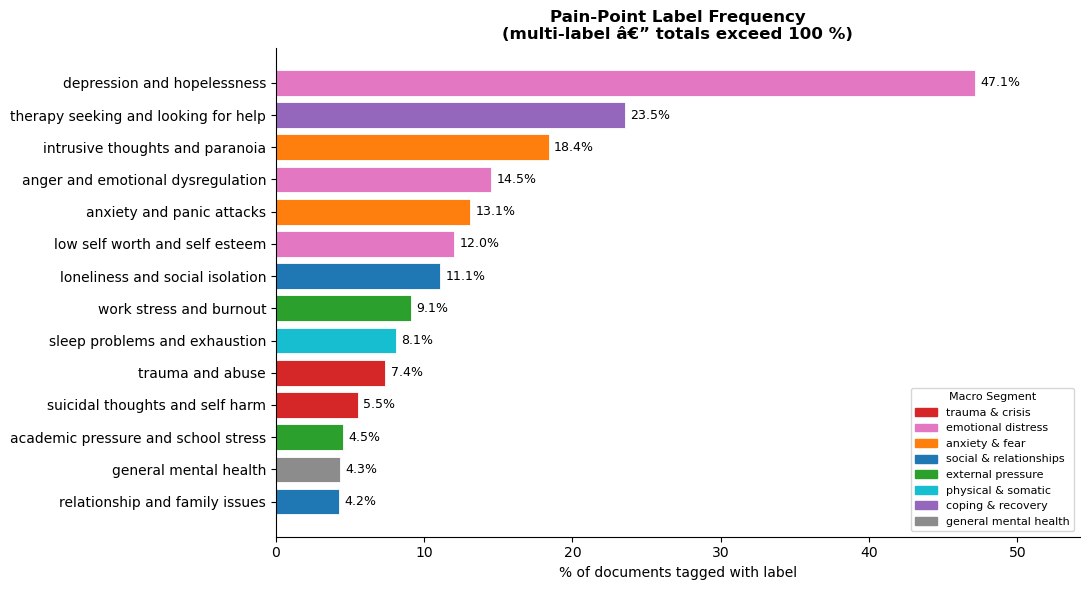

In [12]:

fig, ax = plt.subplots(figsize=(11, 6))

labels_ord = [l for l, _ in pain_point_freq.most_common()]
counts_ord = [c for _, c in pain_point_freq.most_common()]
pcts_ord   = [c / len(master_df) * 100 for c in counts_ord]

bar_colours = [
    SEGMENT_PALETTE.get(_sub_to_macro.get(l, "coping & recovery"), "#aaa")
    for l in labels_ord
]

bars = ax.barh(labels_ord[::-1], pcts_ord[::-1],
               color=bar_colours[::-1],
               edgecolor="white", linewidth=0.6)
ax.bar_label(bars, fmt="%.1f%%", padding=4, fontsize=9)

legend_patches = [
    mpatches.Patch(color=col, label=seg)
    for seg, col in SEGMENT_PALETTE.items()
]
ax.legend(handles=legend_patches, title="Macro Segment",
          loc="lower right", fontsize=8, title_fontsize=8)
ax.set_xlabel("% of documents tagged with label", fontsize=10)
ax.set_title(
    "Pain-Point Label Frequency\n(multi-label â€” totals exceed 100 %)",
    fontsize=12, fontweight="bold")
ax.set_xlim(0, max(pcts_ord) * 1.15)
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig("fig1_painpoint_frequency.png", dpi=150)
plt.show()

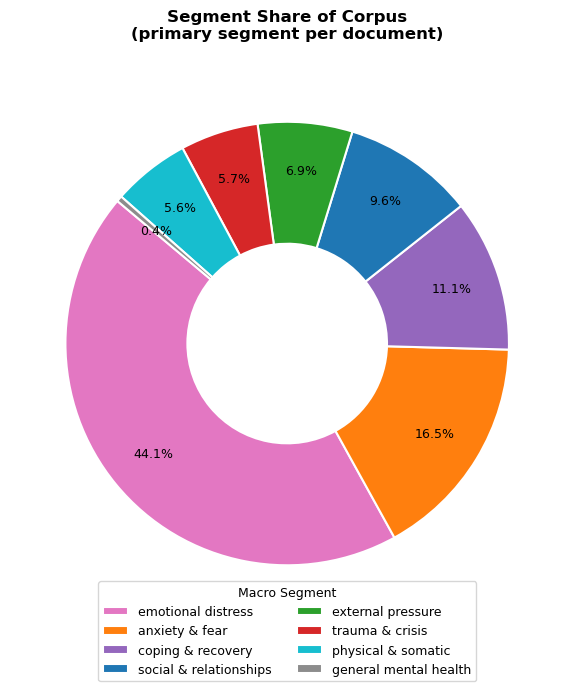

In [13]:

fig, ax = plt.subplots(figsize=(8, 7))

seg_labels = segment_share.index.tolist()
seg_sizes  = segment_share.values.tolist()
seg_cols   = [SEGMENT_PALETTE[s] for s in seg_labels]

wedges, _, autotexts = ax.pie(
    seg_sizes, colors=seg_cols, autopct="%1.1f%%",
    startangle=140, pctdistance=0.78,
    wedgeprops={"width": 0.55, "edgecolor": "white", "linewidth": 1.5}
)
for at in autotexts:
    at.set_fontsize(9)

ax.legend(wedges, seg_labels, title="Macro Segment",
          loc="lower center", bbox_to_anchor=(0.5, -0.12),
          ncol=2, fontsize=9, title_fontsize=9)
ax.set_title("Segment Share of Corpus\n(primary segment per document)",
             fontsize=12, fontweight="bold", pad=20)
plt.tight_layout()
plt.savefig("fig2_segment_share_donut.png", dpi=150)
plt.show()

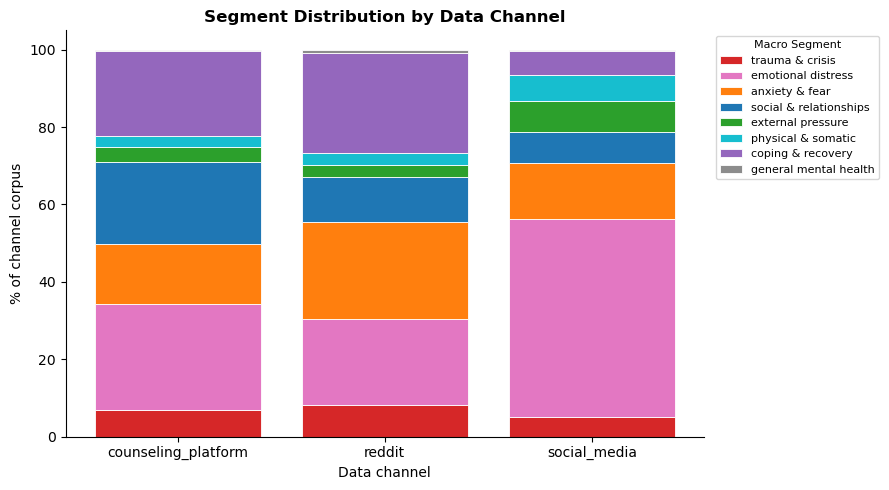

In [14]:

channel_seg = (
    master_df
    .groupby(["data_channel", "segment_macro"])
    .size()
    .unstack(fill_value=0)
)
channel_seg_pct = channel_seg.div(channel_seg.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(9, 5))
bottom = np.zeros(len(channel_seg_pct))

for seg in SEGMENT_PRIORITY:
    if seg not in channel_seg_pct.columns:
        continue
    vals = channel_seg_pct[seg].values
    ax.bar(channel_seg_pct.index, vals, bottom=bottom,
           color=SEGMENT_PALETTE[seg], label=seg,
           edgecolor="white", linewidth=0.6)
    bottom += vals

ax.set_ylabel("% of channel corpus", fontsize=10)
ax.set_xlabel("Data channel", fontsize=10)
ax.set_title("Segment Distribution by Data Channel",
             fontsize=12, fontweight="bold")
ax.legend(title="Macro Segment", bbox_to_anchor=(1.01, 1),
          loc="upper left", fontsize=8, title_fontsize=8)
ax.set_ylim(0, 105)
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig("fig3_segment_by_channel.png", dpi=150)
plt.show()

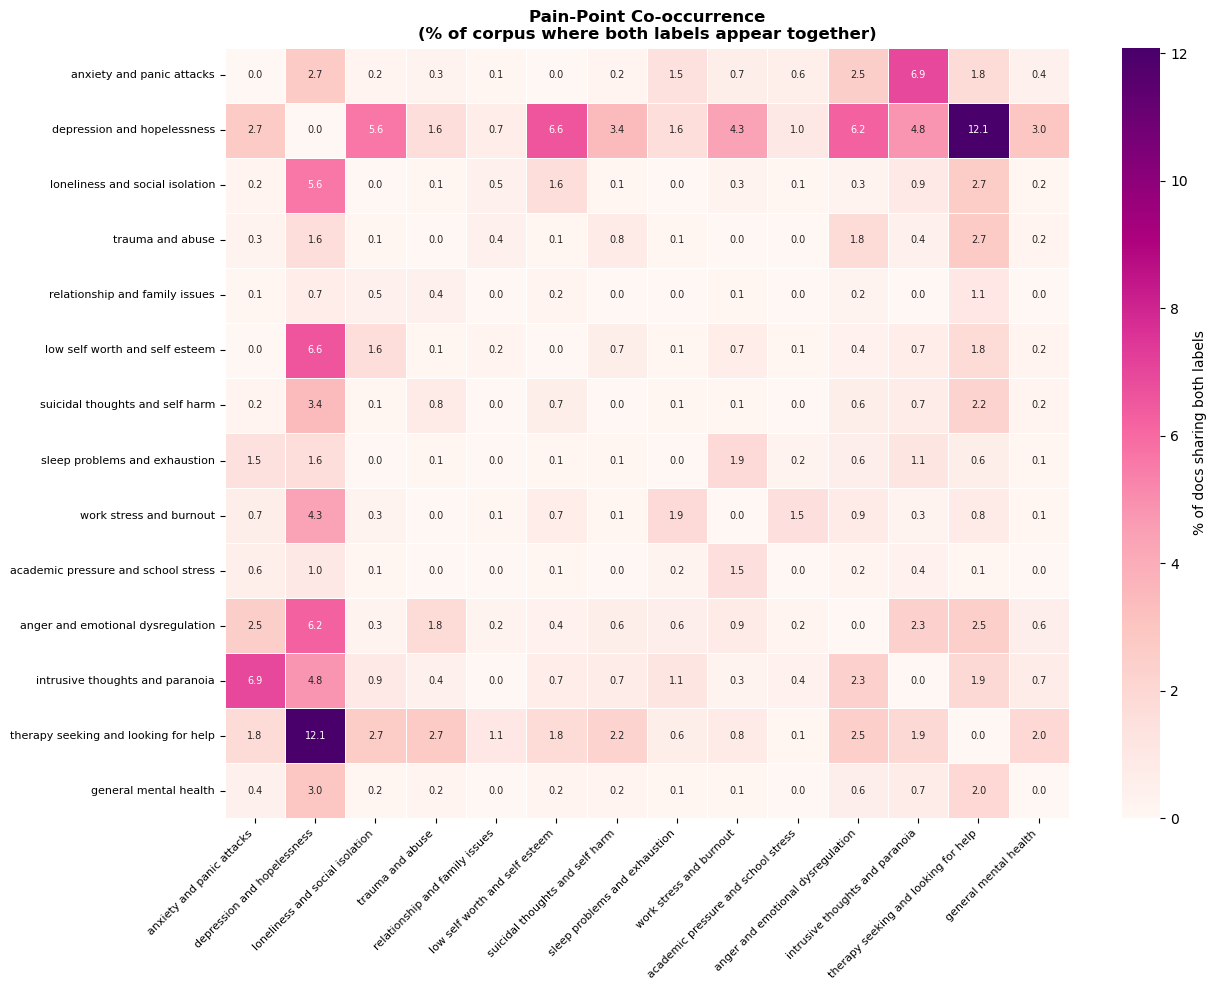

In [15]:

co_matrix = pd.DataFrame(0, index=PAIN_POINT_LABELS, columns=PAIN_POINT_LABELS)
for labels_row in master_df["pain_point_labels"]:
    for a, b in itertools.combinations(labels_row, 2):
        co_matrix.loc[a, b] += 1
        co_matrix.loc[b, a] += 1

co_pct = co_matrix / len(master_df) * 100

fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(co_pct, cmap="RdPu", linewidths=0.4, linecolor="white",
            annot=True, fmt=".1f", annot_kws={"size": 7}, ax=ax,
            cbar_kws={"label": "% of docs sharing both labels"})
ax.set_title(
    "Pain-Point Co-occurrence\n(% of corpus where both labels appear together)",
    fontsize=12, fontweight="bold")
plt.xticks(rotation=45, ha="right", fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.savefig("fig4_cooccurrence_heatmap.png", dpi=150)
plt.show()

## 4 Â· Word Clouds â€” per Macro Segment

Most characteristic words in each segment's documents.

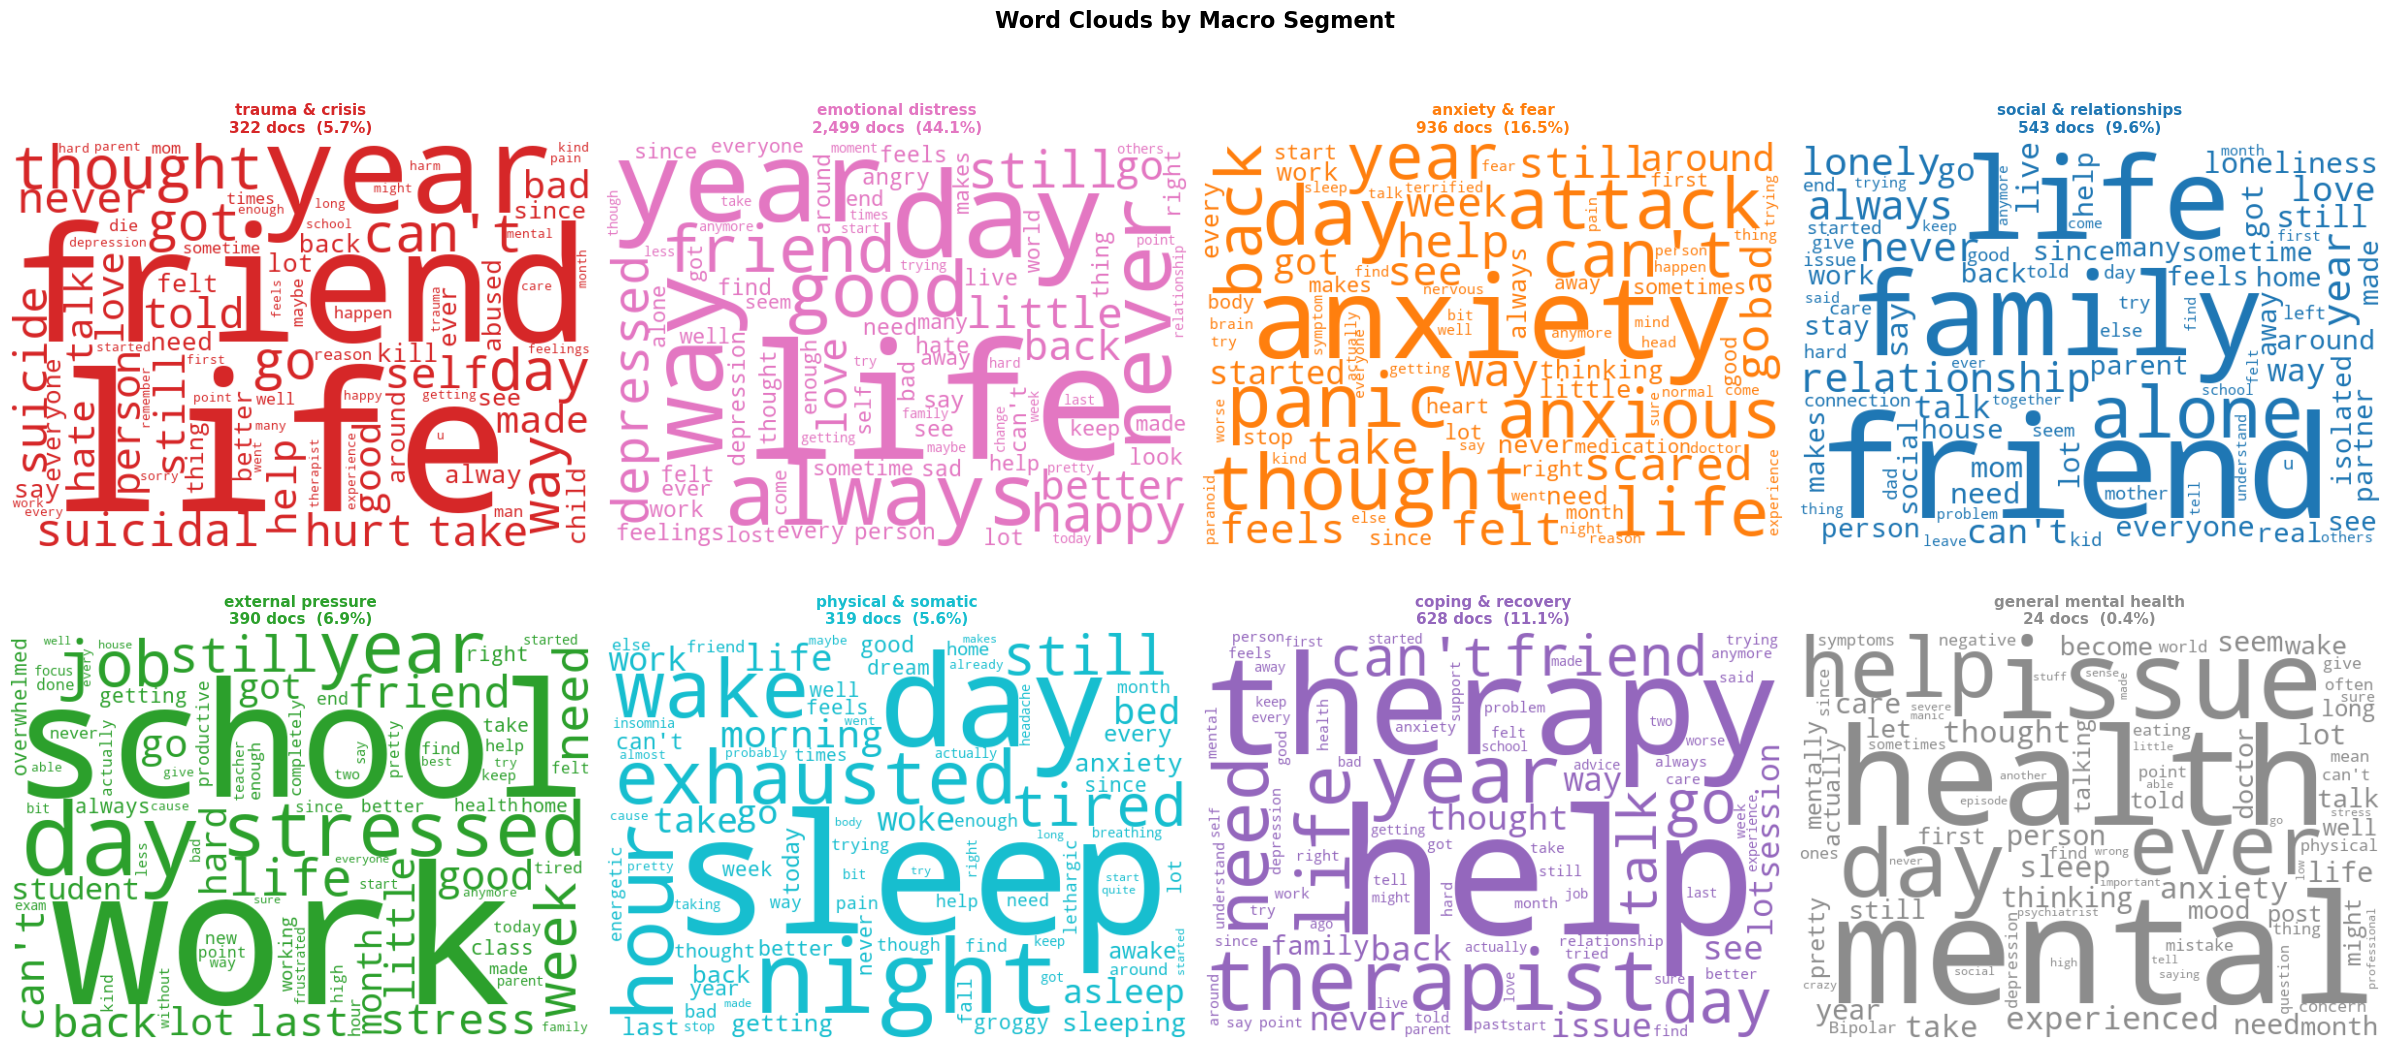

In [16]:

STOP_WORDS = set(stopwords.words("english")) | {
    "feel", "feeling", "know", "think", "want", "really",
    "would", "could", "get", "one", "like", "make",
    "time", "things", "going", "much", "also", "even",
    "im", "ive", "dont", "cant", "doesnt", "isnt",
    "something", "anything", "everything", "nothing",
    "people", "someone", "anyone",
}

def _segment_corpus(segment):
    mask = master_df["segment_macro"] == segment
    return " ".join(master_df.loc[mask, "cleaned_text"].dropna().tolist())

fig, axes = plt.subplots(2, 4, figsize=(24, 11))  
fig.suptitle("Word Clouds by Macro Segment", fontsize=16,
             fontweight="bold", y=1.01)

for ax, segment in zip(axes.flat, SEGMENT_PRIORITY):
    colour = SEGMENT_PALETTE[segment]
    corpus = _segment_corpus(segment)

    if not corpus.strip():
        ax.set_visible(False)
        continue

    wc = WordCloud(
        width=600, height=420,
        background_color="white",
        stopwords=STOP_WORDS,
        color_func=lambda *a, **kw: colour,
        max_words=80,
        prefer_horizontal=0.85,
        collocations=False,
    ).generate(corpus)

    n_docs = (master_df["segment_macro"] == segment).sum()
    pct    = n_docs / len(master_df) * 100

    ax.imshow(wc, interpolation="bilinear")
    ax.axis("off")
    ax.set_title(f"{segment}\n{n_docs:,} docs  ({pct:.1f}%)",
                 fontsize=11, fontweight="bold", color=colour, pad=6)

for ax in axes.flat[len(SEGMENT_PRIORITY):]:
    ax.set_visible(False)

plt.tight_layout()
plt.savefig("fig5_wordclouds_per_segment.png", dpi=150, bbox_inches="tight")
plt.show()

  Running spaCy age extraction … (this may take a moment)
  Age signal found in : 312 / 5,661 rows  (5.5%)

  Age group counts (rows with clear NLP signal only):
    Child (0–12)           :    99  ( 31.7%)  ▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪
    Teen (13–17)           :    80  ( 25.6%)  ▪▪▪▪▪▪▪▪▪▪▪▪
    Young Adult (18–24)    :    57  ( 18.3%)  ▪▪▪▪▪▪▪▪▪
    Adult (25–34)          :    40  ( 12.8%)  ▪▪▪▪▪▪
    Adult (35–44)          :    24  (  7.7%)  ▪▪▪
    Adult (45–54)          :     3  (  1.0%)  
    Senior (65+)           :     9  (  2.9%)  ▪

  Numeric age stats:
    Mean   : 19.7
    Median : 15
    Std    : 14.0
    Range  : 2 – 99


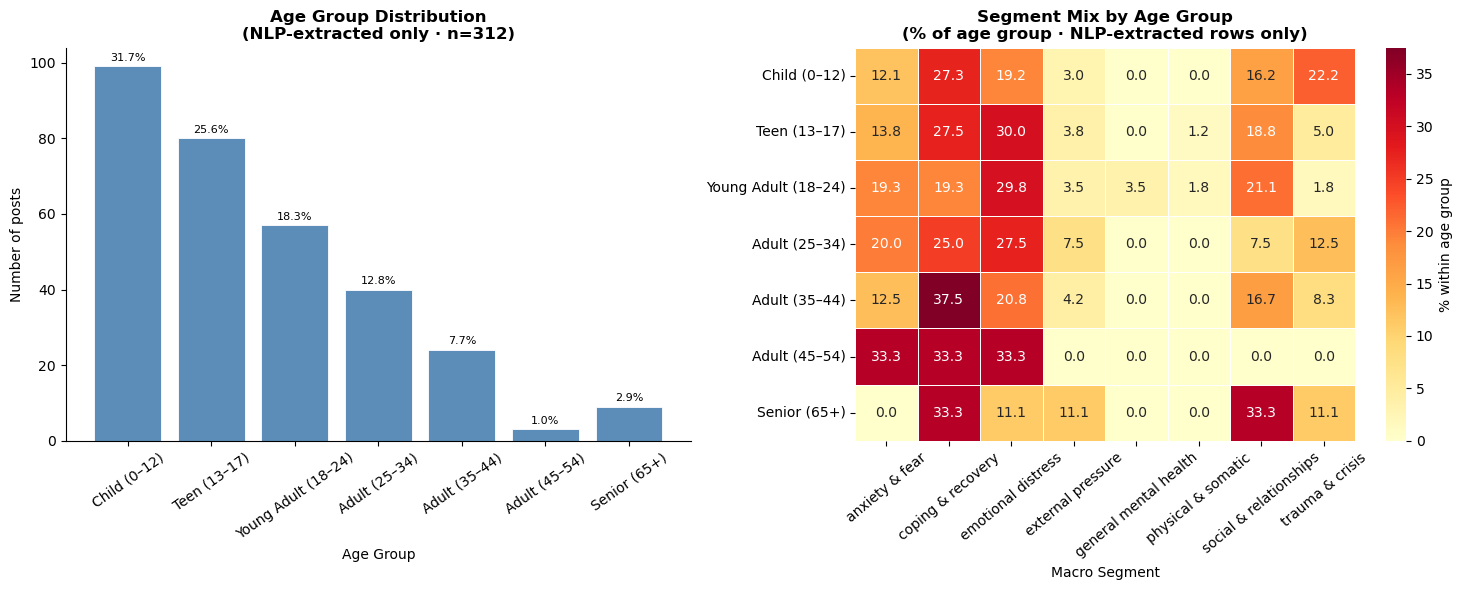

In [17]:
# ── CELL 5 · Age Extraction via NLP ─────────────────────────────────────────
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ── 1. NLP age-signal maps ────────────────────────────────────────────────────
# Life-stage words → representative midpoint age
# spaCy will detect these as entities or we catch them via token matching
LIFE_STAGE_MAP = {
    "toddler": 2, "child": 9, "kid": 9, "tween": 11,
    "preteen": 11, "teen": 15, "teenager": 15, "adolescent": 15,
    "adolescence": 15, "minor": 15, "youth": 17,
    "young adult": 22, "college student": 20, "university student": 20,
    "grad student": 24, "graduate student": 24,
    "adult": 35, "middle-aged": 45, "middle aged": 45,
    "older adult": 65, "elderly": 72, "senior": 67,
    "senior citizen": 72, "retiree": 67, "retired": 67,
}

AGE_BINS   = [0, 12, 17, 24, 34, 44, 54, 64, 120]
AGE_LABELS = [
    "Child (0–12)", "Teen (13–17)", "Young Adult (18–24)",
    "Adult (25–34)", "Adult (35–44)", "Adult (45–54)",
    "Adult (55–64)", "Senior (65+)"
]

# ── 2. spaCy-based extraction function ───────────────────────────────────────
# Pattern: number token immediately followed by "year(s) old" / "yo" / "y/o"
# Also catches: "I'm X" / "I am X" when X is a CARDINAL near age-words
# Fixed regex patterns:
_AGE_CONTEXT = re.compile(r'\b(?:i[\'"]?m|i am|age[d]?|turned|turning|just turned|almost|nearly)\s+(\d{1,2})\b', re.IGNORECASE)
_YEARS_OLD = re.compile(r'\b(\d{1,2})\s*(?:years?\s*old|year[- ]old|yo\b|y\.?o\.?\b|yr\.?s?\s*old)', re.IGNORECASE)

def extract_age_nlp(text):
    """
    Returns (numeric_age, age_group_label) using spaCy NLP.
    Returns (None, None) if no reliable age signal is found.
    Only rows with a clear signal are kept in the age stats.
    """
    t = str(text)

    # ── Pass 1: hard regex patterns (highest precision) ──────────────────────
    for pattern in [_YEARS_OLD, _AGE_CONTEXT]:
        m = pattern.search(t)
        if m:
            age = int(m.group(1))
            if 5 <= age <= 99:
                label = pd.cut([age], bins=AGE_BINS, labels=AGE_LABELS, right=True)[0]
                return age, str(label)

    # ── Pass 2: spaCy CARDINAL entities + proximity check ────────────────────
    doc = nlp(t[:512])  # spaCy's en_core_web_sm, already loaded in cell 1

    for ent in doc.ents:
        if ent.label_ == "CARDINAL":
            try:
                age = int(ent.text.strip())
            except ValueError:
                continue
            if not (5 <= age <= 99):
                continue

            # Grab surrounding 6-token window
            window_start = max(0, ent.start - 3)
            window_end   = min(len(doc), ent.end + 3)
            context_text = doc[window_start:window_end].text.lower()

            age_triggers = {
                "year", "years", "old", "age", "aged", "yo", "yr",
                "teen", "adult", "im", "i'm", "turned", "turning"
            }
            if any(trigger in context_text for trigger in age_triggers):
                label = pd.cut([age], bins=AGE_BINS, labels=AGE_LABELS, right=True)[0]
                return age, str(label)

    # ── Pass 3: life-stage keyword matching via spaCy tokens ─────────────────
    doc_lower = t.lower()

    # Check multi-word phrases first (longer = more specific)
    for phrase in sorted(LIFE_STAGE_MAP, key=len, reverse=True):
        if phrase in doc_lower:
            # Confirm the phrase is an actual token sequence, not noise
            phrase_tokens = phrase.split()
            doc_tokens    = [tok.lower_ for tok in doc]
            for i in range(len(doc_tokens) - len(phrase_tokens) + 1):
                if doc_tokens[i:i+len(phrase_tokens)] == phrase_tokens:
                    age   = LIFE_STAGE_MAP[phrase]
                    label = pd.cut([age], bins=AGE_BINS, labels=AGE_LABELS, right=True)[0]
                    return age, str(label)

    # ── No signal found → excluded from stats ────────────────────────────────
    return None, None


# ── 3. Apply to master_df ─────────────────────────────────────────────────────
print("  Running spaCy age extraction … (this may take a moment)")

master_df[["extracted_age", "age_group"]] = master_df["cleaned_text"].apply(
    lambda t: pd.Series(extract_age_nlp(t))
)

# Only rows with a clear age signal
age_df = master_df[master_df["extracted_age"].notna()].copy()

coverage = len(age_df)
print(f"  Age signal found in : {coverage:,} / {len(master_df):,} rows  "
      f"({coverage / len(master_df) * 100:.1f}%)\n")

# ── 4. Statistics (age_df only — no-signal rows excluded) ────────────────────
print("  Age group counts (rows with clear NLP signal only):")
ag_counts = (
    age_df["age_group"]
    .value_counts()
    .reindex(AGE_LABELS)
    .dropna()
    .astype(int)
)
for group, cnt in ag_counts.items():
    pct = cnt / coverage * 100
    print(f"    {group:22s} : {cnt:>5,}  ({pct:5.1f}%)  {'▪' * int(pct / 2)}")

numeric_ages = age_df["extracted_age"]
print(f"\n  Numeric age stats:")
print(f"    Mean   : {numeric_ages.mean():.1f}")
print(f"    Median : {numeric_ages.median():.0f}")
print(f"    Std    : {numeric_ages.std():.1f}")
print(f"    Range  : {int(numeric_ages.min())} – {int(numeric_ages.max())}")

# ── 5. Visualisation ─────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 5a · Age group bar chart
axes[0].bar(ag_counts.index, ag_counts.values,
            color="#5b8db8", edgecolor="white", linewidth=0.6)
axes[0].set_title(
    f"Age Group Distribution\n(NLP-extracted only · n={coverage:,})",
    fontweight="bold"
)
axes[0].set_xlabel("Age Group")
axes[0].set_ylabel("Number of posts")
axes[0].tick_params(axis="x", rotation=35)
for bar, val in zip(axes[0].patches, ag_counts.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + coverage * 0.003,
        f"{val / coverage * 100:.1f}%",
        ha="center", va="bottom", fontsize=8
    )
sns.despine(ax=axes[0])

# 5b · Age group × macro segment heatmap (% within age group)
cross = (
    age_df
    .groupby(["age_group", "segment_macro"])
    .size()
    .unstack(fill_value=0)
)
cross_pct = cross.div(cross.sum(axis=1), axis=0) * 100
cross_pct = cross_pct.reindex([l for l in AGE_LABELS if l in cross_pct.index])

sns.heatmap(
    cross_pct, cmap="YlOrRd", annot=True, fmt=".1f",
    linewidths=0.4, linecolor="white",
    cbar_kws={"label": "% within age group"},
    ax=axes[1]
)
axes[1].set_title(
    "Segment Mix by Age Group\n(% of age group · NLP-extracted rows only)",
    fontweight="bold"
)
axes[1].set_xlabel("Macro Segment")
axes[1].set_ylabel("")
axes[1].tick_params(axis="x", rotation=40)

plt.tight_layout()
plt.savefig("fig6_age_group_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

Loading transformer model for age validation...


Loading weights: 100%|██████████| 515/515 [00:00<00:00, 947.35it/s, Materializing param=model.shared.weight]                                   


✅ Transformer model loaded

EXTRACTING CURRENT AGES (No past references)
Processing 5,661 rows...


100%|██████████| 5661/5661 [00:11<00:00, 501.49it/s] 



✅ Current age found in: 164 / 5,661 rows (2.9%)

AGE GROUP DISTRIBUTION (Current age only - Under 18 aggregated)

  Under 18               :    48  ( 29.3%)  ██████████████
  Young Adult (18–24)    :    53  ( 32.3%)  ████████████████
  Adult (25–34)          :    36  ( 22.0%)  ██████████
  Adult (35–44)          :     8  (  4.9%)  ██
  Adult (45–54)          :     5  (  3.0%)  █
  Senior (65+)           :     5  (  3.0%)  █

📊 Under 18 age breakdown:
   Age 5: 2 posts (4.2% of under 18 group)
   Age 13: 1 posts (2.1% of under 18 group)
   Age 14: 5 posts (10.4% of under 18 group)
   Age 15: 6 posts (12.5% of under 18 group)
   Age 16: 27 posts (56.2% of under 18 group)
   Age 17: 7 posts (14.6% of under 18 group)

📊 Numeric age statistics (n=164):
  Mean age   : 24.4 years
  Median age : 21 years
  Std dev    : 13.9
  Age range  : 5 – 99

SAMPLE EXTRACTIONS (Current ages only)

1. Age 25 (Adult (25–34))
   Shrooms After Effects Has anyone had any permanent effects from a shrooms trip?

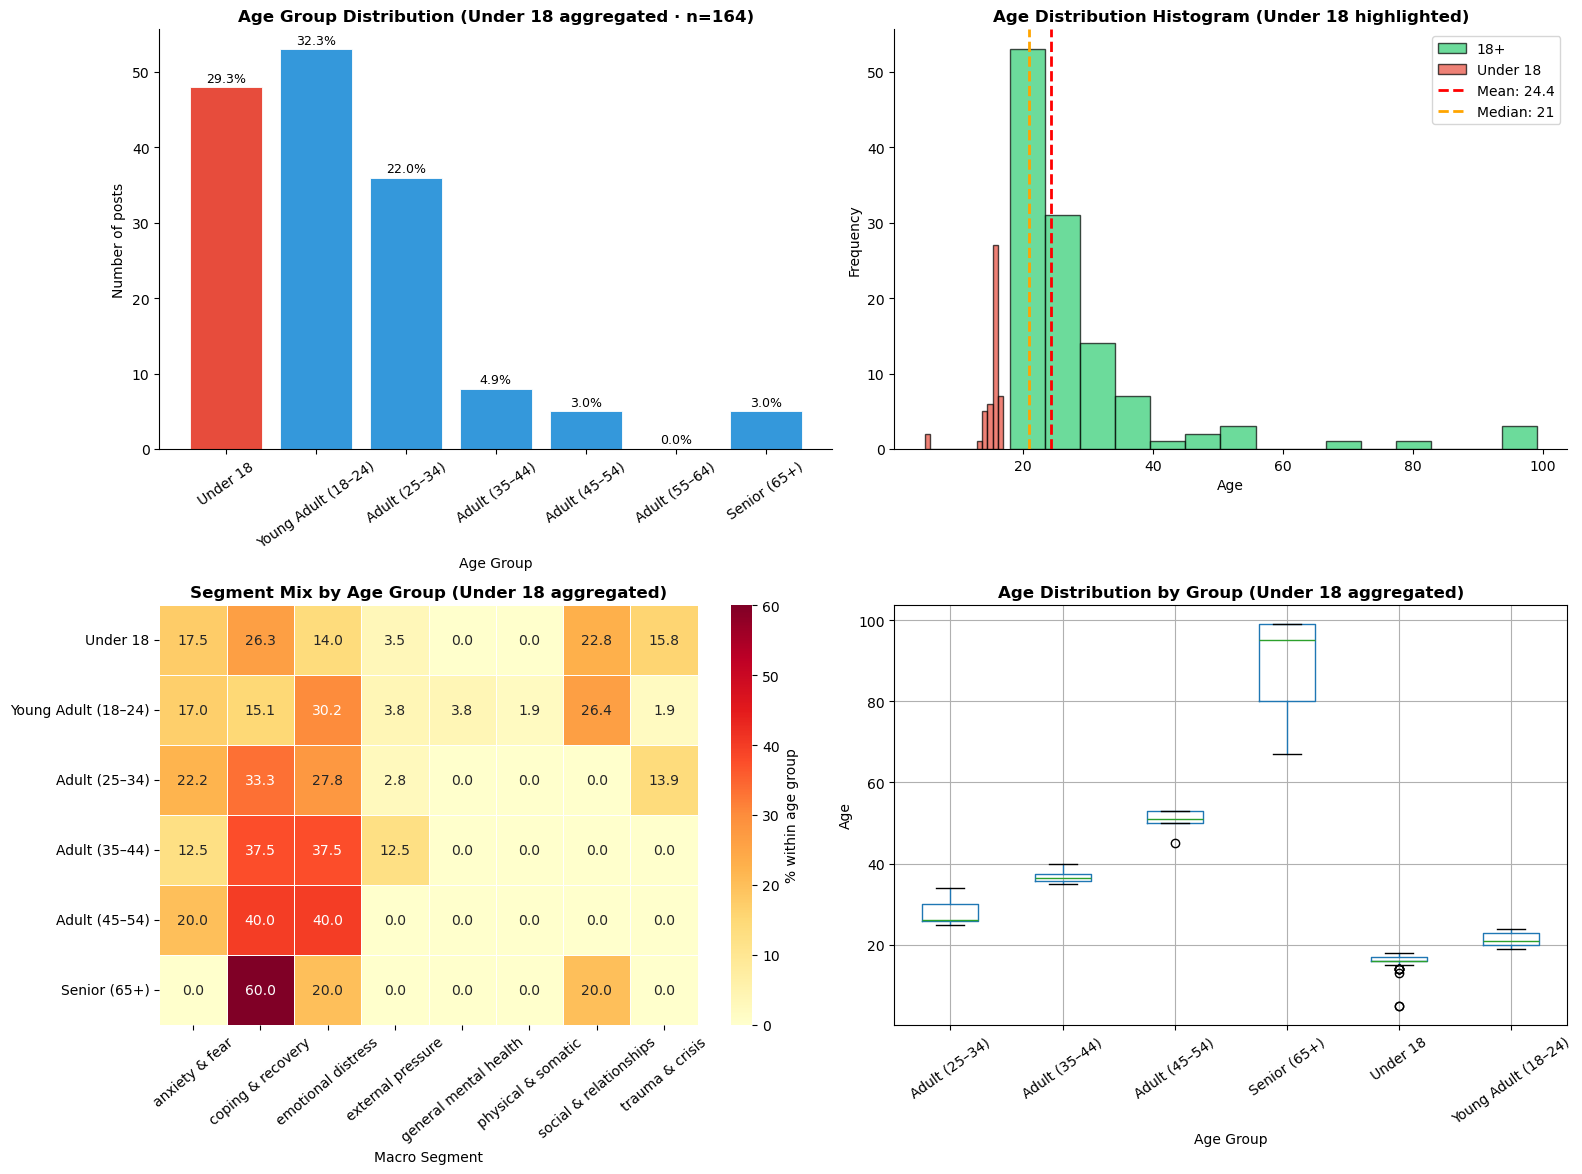


FINAL SUMMARY
✅ Total posts analyzed:        5,661
✅ Posts with current age:      164 (2.9%)
✅ Posts without age signal:    5,497 (97.1%)

📊 Age breakdown:
   Under 18:                    48 (29.3% of age-detected posts)
   18+:                         116 (70.7% of age-detected posts)

📊 Most common age group:       Young Adult (18–24)
📊 Average age:                 24.4 years

💾 Results saved to:
   - master_df['extracted_age']
   - master_df['age_group']
   - Figure: fig6_age_extraction_results.png

📁 Full age extraction results saved to: age_extraction_results.csv


In [32]:
# ── CELL 5 · Complete Age Extraction (Current Age Only - Modified) ────────────
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import torch
from transformers import pipeline

tqdm.pandas()

# ── 1. Age bins & labels (MODIFIED: Under 18 category, no child breakdown) ───
AGE_BINS = [0, 18, 24, 34, 44, 54, 64, 120]
AGE_LABELS = [
    "Under 18",           # Changed from Child/Teen breakdown
    "Young Adult (18–24)",
    "Adult (25–34)", 
    "Adult (35–44)",
    "Adult (45–54)",
    "Adult (55–64)",
    "Senior (65+)"
]

def bucket_age(age):
    """Convert numeric age to age group label."""
    # Filter out ages under 18 - we'll handle them separately
    if age < 18:
        return "Under 18"
    label = pd.cut([age], bins=AGE_BINS, labels=AGE_LABELS, right=True)[0]
    return str(label)

# ── 2. First-person life-stage phrases (current only) ────────────────────────
CURRENT_STAGE_MAP = {
    "i'm a teenager": 16,      # Map to 16 (still under 18)
    "i am a teenager": 16,
    "i'm a teen": 16,
    "i am a teen": 16,
    "i'm a kid": 15,           # Will become "Under 18"
    "i am a kid": 15,
    "i'm a child": 12,         # Will become "Under 18"
    "i am a child": 12,
    "i'm an adult": 30,
    "i am an adult": 30,
    "i'm a young adult": 22,
    "i am a young adult": 22,
    "i'm a senior": 67,
    "i am a senior": 67,
    "i'm retired": 67,
    "i am retired": 67,
    "i'm in my 20s": 25,
    "i'm in my twenties": 25,
    "i'm in my 30s": 35,
    "i'm in my thirties": 35,
    "i'm in my 40s": 45,
    "i'm in my forties": 45,
    "i'm in my 50s": 55,
    "i'm in my fifties": 55,
    "i'm in my 60s": 65,
    "i'm in my sixties": 65,
}

# ── 3. Regex patterns for CURRENT age only (excludes past references) ─────────
CURRENT_AGE_PATTERNS = [
    # Pattern 1: "I'm 25", "I'm 25 years old"
    (
        r'i[\'\"]?m\s+(\d{1,2})\s*(?:years?\s+old)?\b(?![-\s]*(?:when|since|back|at\s+age))',
        'current'
    ),
    # Pattern 2: "I am 25", "I am 25 years old"
    (
        r'i\s+am\s+(\d{1,2})\s*(?:years?\s+old)?\b(?![-\s]*(?:when|since|back|at\s+age))',
        'current'
    ),
    # Pattern 3: "25M", "25F", "25NB" at beginning of post or after punctuation
    (r'(?:^|[\s\(])(\d{1,2})\s*[fFmMnN][bB]?\b', 'current'),
    # Pattern 4: "25 years old" with implied "I'm"
    (r'(\d{1,2})\s+years?\s+old\s+(?:and|with|but|so|,|\.)', 'current'),
    # Pattern 5: "Age: 25", "age 25"
    (r'age[:\s]+(\d{1,2})\b', 'current'),
    # Pattern 6: "25 yo", "25 y/o"
    (r'(\d{1,2})\s+y(?:o|\.o\.?)\b', 'current'),
]

# Past reference patterns (to EXCLUDE)
PAST_AGE_PATTERNS = [
    r'since\s+i\s+was\s+(\d{1,2})',
    r'when\s+i\s+was\s+(\d{1,2})',
    r'back\s+when\s+i\s+was\s+(\d{1,2})',
    r'at\s+age\s+(\d{1,2})',
    r'aged\s+(\d{1,2})',
    r'from\s+age\s+(\d{1,2})',
    r'i\s+was\s+(\d{1,2})\s*(?:years?\s+old)?',
    r'since\s+(\d{1,2})\s*(?!years?\s+old\s+and)',
    r'starting\s+at\s+age\s+(\d{1,2})',
    r'began\s+at\s+age\s+(\d{1,2})',
]

# ── 4. Load transformer model for validation ──────────────────────────────────
print("Loading transformer model for age validation...")
try:
    classifier = pipeline(
        "zero-shot-classification",
        model="facebook/bart-large-mnli",
        device=0 if torch.cuda.is_available() else -1,
    )
    transformer_available = True
    print("✅ Transformer model loaded")
except Exception as e:
    print(f"⚠️ Could not load transformer model: {e}")
    print("   Falling back to rule-based extraction only")
    transformer_available = False

# ── 5. Core extraction function ──────────────────────────────────────────────
def extract_current_age(text):
    """Extract the speaker's CURRENT age at time of posting."""
    if not isinstance(text, str):
        return None, None

    text_lower = text.lower()
    text_original = text

    # ── STEP 1: Extract from CURRENT age patterns ────────────────────────────
    for pattern, _ in CURRENT_AGE_PATTERNS:
        matches = re.finditer(pattern, text_lower)
        for match in matches:
            age = int(match.group(1))
            if not (5 <= age <= 99):
                continue

            # Get context around the match (40 chars each side)
            start = max(0, match.start() - 40)
            end = min(len(text_lower), match.end() + 40)
            context = text_lower[start:end]

            # Check for past indicators in context
            past_indicators = [
                'since i was',
                'when i was',
                'back when',
                'used to be',
                'at that age',
                'back then',
                'at age',
                'aged',
            ]
            is_past_reference = any(indicator in context for indicator in past_indicators)

            # Also check if there's explicit present tense markers
            present_markers = [
                'i am', "i'm", "i've been", "currently", "now", "today",
            ]
            has_present_marker = any(marker in context for marker in present_markers)

            # Accept if: not a past reference OR has present marker
            if not is_past_reference or (is_past_reference and has_present_marker):
                # ── STEP 2: Validate with transformer (if available) ────────
                if transformer_available and len(text_original) > 20:
                    try:
                        validation_text = text_original[
                            max(0, match.start() - 100):
                            min(len(text_original), match.end() + 100)
                        ]
                        result = classifier(
                            validation_text,
                            candidate_labels=[
                                "speaker's current age",
                                "past age",
                                "quantity or duration",
                            ],
                            hypothesis_template="This text refers to the {}.",
                        )

                        if result['labels'][0] == "speaker's current age" and result['scores'][0] > 0.5:
                            return age, bucket_age(age)
                        elif not is_past_reference and age <= 25:
                            # For younger ages, be more forgiving with transformer
                            if result['scores'][0] > 0.3:
                                return age, bucket_age(age)
                    except Exception:
                        pass

                # Rule-based acceptance
                return age, bucket_age(age)

    # ── STEP 3: Check life-stage phrases ──────────────────────────────────────
    for phrase, age in sorted(CURRENT_STAGE_MAP.items(), key=lambda x: -len(x[0])):
        if phrase in text_lower:
            # Verify it's current (not "when I was a teenager")
            start = max(0, text_lower.find(phrase) - 30)
            end = min(len(text_lower), text_lower.find(phrase) + len(phrase) + 30)
            context = text_lower[start:end]

            past_markers = ['when i was', 'back when', 'used to be', 'as a']
            if not any(marker in context for marker in past_markers):
                return age, bucket_age(age)

    # ── STEP 4: Check for Reddit-style age declarations ───────────────────────
    reddit_pattern = r'(\d{1,2})\s*\[\s*[MFmf]\s*\]'
    match = re.search(reddit_pattern, text_original)
    if match:
        age = int(match.group(1))
        if 5 <= age <= 99:
            return age, bucket_age(age)

    return None, None

# ── 6. Apply to dataframe with progress bar ───────────────────────────────────
print("\n" + "=" * 70)
print("EXTRACTING CURRENT AGES (No past references)")
print("=" * 70)
print(f"Processing {len(master_df):,} rows...")

master_df[["extracted_age", "age_group"]] = master_df["cleaned_text"].progress_apply(
    lambda t: pd.Series(extract_current_age(t))
)

# ── 7. Results summary ───────────────────────────────────────────────────────
age_df = master_df[master_df["extracted_age"].notna()].copy()
coverage = len(age_df)

print(f"\n✅ Current age found in: {coverage:,} / {len(master_df):,} rows ({coverage/len(master_df)*100:.1f}%)")

# ── 8. Age group statistics (with Under 18 aggregated) ───────────────────────
print("\n" + "=" * 70)
print("AGE GROUP DISTRIBUTION (Current age only - Under 18 aggregated)")
print("=" * 70)

# Count how many are under 18
under_18_count = (age_df["extracted_age"] < 18).sum()
under_18_pct = under_18_count / coverage * 100 if coverage > 0 else 0

print(f"\n  {'Under 18':22s} : {under_18_count:>5,}  ({under_18_pct:5.1f}%)  {'█' * int(under_18_pct / 2)}")

# Now get counts for 18+ groups
ag_counts = (
    age_df[age_df["extracted_age"] >= 18]["age_group"]
    .value_counts()
    .reindex(AGE_LABELS[1:])  # Skip "Under 18" in labels
    .dropna()
    .astype(int)
)

for group, cnt in ag_counts.items():
    pct = cnt / coverage * 100 if coverage > 0 else 0
    bar_length = int(pct / 2)
    print(f"  {group:22s} : {cnt:>5,}  ({pct:5.1f}%)  {'█' * bar_length}")

# Also show the breakdown of UNDER 18 ages if you want to see the distribution
print("\n📊 Under 18 age breakdown:")
under_18_ages = age_df[age_df["extracted_age"] < 18]["extracted_age"].value_counts().sort_index()
for age, count in under_18_ages.items():
    print(f"   Age {int(age)}: {count} posts ({count/under_18_count*100:.1f}% of under 18 group)")

# Numeric age stats
numeric_ages = age_df["extracted_age"]
print(f"\n📊 Numeric age statistics (n={coverage:,}):")
print(f"  Mean age   : {numeric_ages.mean():.1f} years")
print(f"  Median age : {numeric_ages.median():.0f} years")
print(f"  Std dev    : {numeric_ages.std():.1f}")
print(f"  Age range  : {int(numeric_ages.min())} – {int(numeric_ages.max())}")

# ── 9. Show example extractions ───────────────────────────────────────────────
print("\n" + "=" * 70)
print("SAMPLE EXTRACTIONS (Current ages only)")
print("=" * 70)

for idx, (i, row) in enumerate(age_df.head(15).iterrows()):
    age = int(row['extracted_age'])
    text = row['cleaned_text'][:200]
    age_str = str(age)
    if age_str in text:
        highlighted = text.replace(age_str, f"**{age_str}**")
    else:
        highlighted = text
    # Mark under 18 with a note
    under_18_note = " [UNDER 18]" if age < 18 else ""
    print(f"\n{idx+1}. Age {age}{under_18_note} ({row['age_group']})")
    print(f"   {highlighted}...")

# ── 10. Visualizations (MODIFIED for Under 18 category) ──────────────────────
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 10a · Age group bar chart (with Under 18 as first bar)
ax1 = axes[0, 0]

# Create combined data for plotting
all_groups = ["Under 18"] + [g for g in AGE_LABELS if g != "Under 18"]
# Create counts list matching the groups
all_counts = [under_18_count] + [ag_counts.get(group, 0) for group in AGE_LABELS if group != "Under 18"]

# Create colors list matching the length
colors = ['#e74c3c'] + ['#3498db'] * (len(all_groups) - 1)

bars = ax1.bar(
    all_groups,
    all_counts,
    color=colors,
    edgecolor='white',
    linewidth=0.6,
)
ax1.set_title(
    f'Age Group Distribution (Under 18 aggregated · n={coverage:,})',
    fontweight='bold',
    fontsize=12,
)
ax1.set_xlabel('Age Group')
ax1.set_ylabel('Number of posts')
ax1.tick_params(axis='x', rotation=35)
for bar, val in zip(bars, all_counts):
    height = bar.get_height()
    if coverage > 0:
        pct = val / coverage * 100
        ax1.text(
            bar.get_x() + bar.get_width() / 2.,
            height + coverage * 0.002,
            f'{pct:.1f}%',
            ha='center',
            va='bottom',
            fontsize=9,
        )
sns.despine(ax=ax1)

# 10b · Age histogram (with Under 18 highlighted)
ax2 = axes[0, 1]
# Create histogram with under 18 in different color
if len(numeric_ages[numeric_ages >= 18]) > 0:
    ax2.hist(
        numeric_ages[numeric_ages >= 18],
        bins=15,
        color='#2ecc71',
        edgecolor='black',
        alpha=0.7,
        label='18+',
    )
if len(numeric_ages[numeric_ages < 18]) > 0:
    ax2.hist(
        numeric_ages[numeric_ages < 18],
        bins=15,
        color='#e74c3c',
        edgecolor='black',
        alpha=0.7,
        label='Under 18',
    )
ax2.set_title('Age Distribution Histogram (Under 18 highlighted)', fontweight='bold', fontsize=12)
ax2.set_xlabel('Age')
ax2.set_ylabel('Frequency')
ax2.axvline(
    numeric_ages.mean(),
    color='red',
    linestyle='dashed',
    linewidth=2,
    label=f'Mean: {numeric_ages.mean():.1f}',
)
ax2.axvline(
    numeric_ages.median(),
    color='orange',
    linestyle='dashed',
    linewidth=2,
    label=f'Median: {numeric_ages.median():.0f}',
)
ax2.legend()
sns.despine(ax=ax2)

# 10c · Age group × macro segment heatmap (with Under 18)
ax3 = axes[1, 0]

# Create a dataframe with Under 18 included
age_df_with_under18 = age_df.copy()
age_df_with_under18['age_group_modified'] = age_df_with_under18.apply(
    lambda row: 'Under 18' if row['extracted_age'] < 18 else row['age_group'],
    axis=1
)

if 'segment_macro' in age_df.columns:
    cross = age_df_with_under18.groupby(['age_group_modified', 'segment_macro']).size().unstack(fill_value=0)
    cross_pct = cross.div(cross.sum(axis=1), axis=0) * 100
    
    # Reorder index to put Under 18 first
    all_groups_ordered = ['Under 18'] + [g for g in AGE_LABELS if g != 'Under 18']
    cross_pct = cross_pct.reindex([g for g in all_groups_ordered if g in cross_pct.index])

    sns.heatmap(
        cross_pct,
        cmap='YlOrRd',
        annot=True,
        fmt='.1f',
        linewidths=0.4,
        linecolor='white',
        ax=ax3,
        cbar_kws={'label': '% within age group'},
    )
    ax3.set_title('Segment Mix by Age Group (Under 18 aggregated)', fontweight='bold', fontsize=12)
    ax3.set_xlabel('Macro Segment')
    ax3.set_ylabel('')
    ax3.tick_params(axis='x', rotation=40)

# 10d · Box plot by age group (with Under 18 category)
ax4 = axes[1, 1]
# Create a new column with the modified grouping
age_df_with_under18.boxplot(column='extracted_age', by='age_group_modified', ax=ax4, rot=35)
ax4.set_title('Age Distribution by Group (Under 18 aggregated)', fontweight='bold', fontsize=12)
ax4.set_xlabel('Age Group')
ax4.set_ylabel('Age')
plt.suptitle('')  # Remove automatic suptitle

plt.tight_layout()
plt.savefig('fig6_age_extraction_results.png', dpi=150, bbox_inches='tight')
plt.show()

# ── 11. Final summary ───────────────────────────────────────────────────────
print("\n" + "=" * 70)
print("FINAL SUMMARY")
print("=" * 70)
print(f"✅ Total posts analyzed:        {len(master_df):,}")
print(f"✅ Posts with current age:      {coverage:,} ({coverage/len(master_df)*100:.1f}%)")
print(f"✅ Posts without age signal:    {len(master_df)-coverage:,} ({100-coverage/len(master_df)*100:.1f}%)")
print(f"\n📊 Age breakdown:")
print(f"   Under 18:                    {under_18_count} ({under_18_pct:.1f}% of age-detected posts)")
print(f"   18+:                         {coverage - under_18_count} ({(coverage-under_18_count)/coverage*100:.1f}% of age-detected posts)")
if all_counts:
    max_idx = all_counts.index(max(all_counts))
    most_common = all_groups[max_idx] if max_idx < len(all_groups) else 'N/A'
    print(f"\n📊 Most common age group:       {most_common}")
print(f"📊 Average age:                 {numeric_ages.mean():.1f} years")
print(f"\n💾 Results saved to:")
print("   - master_df['extracted_age']")
print("   - master_df['age_group']")
print("   - Figure: fig6_age_extraction_results.png")

# Optional: Save age_df to CSV for further analysis
age_df.to_csv('age_extraction_results.csv', index=False)
print("\n📁 Full age extraction results saved to: age_extraction_results.csv")